### Step 1: Load and Explore (EDA)
In this step, we load the dataset into pandas, inspect its dimensions, data types, summary statistics, and visualize the target distribution along with other key patterns using charts.

--- Shape of Dataset ---
(7043, 21)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Statistical Summary ---


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


C:\Users\DELL\AppData\Local\Temp\ipykernel_10056\2486551819.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


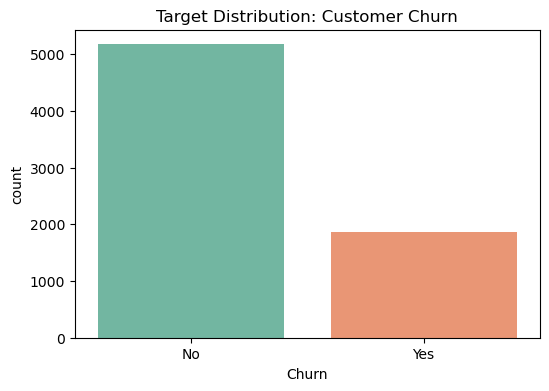

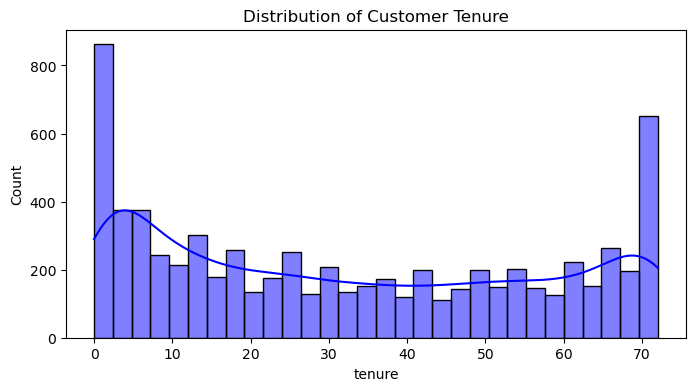

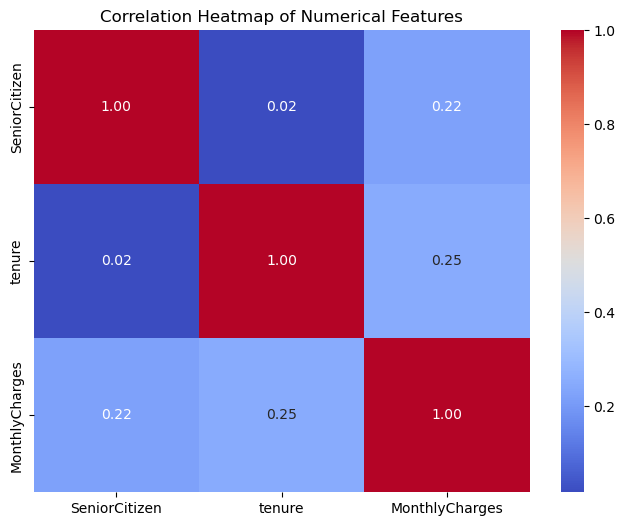

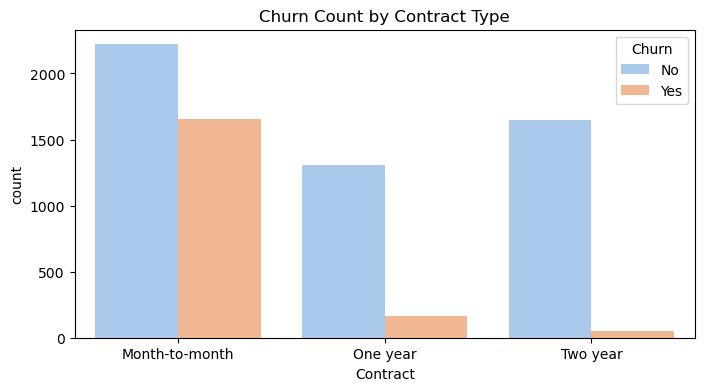

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Basic Info
print("--- Shape of Dataset ---")
print(df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Statistical Summary ---")
display(df.describe())

# Target Distribution Countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Target Distribution: Customer Churn')
plt.show()

# 3 Additional Charts (Histogram, Correlation Heatmap, Categorical plot)
plt.figure(figsize=(8, 4))
sns.histplot(df['tenure'], bins=30, kde=True, color='blue')
plt.title('Distribution of Customer Tenure')
plt.show()

# Correlation Heatmap for numerical columns
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Contract', hue='Churn', palette='pastel')
plt.title('Churn Count by Contract Type')
plt.show()

### Step 2: Clean the Data
 Here we check for and remove duplicate rows, handle missing values (especially in TotalCharges where blank spaces act as hidden NaNs), visualize missing data via a bar chart, and drop irrelevant columns like customerID

Duplicates before: 0
Duplicates after: 0

Missing values per column:
 customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


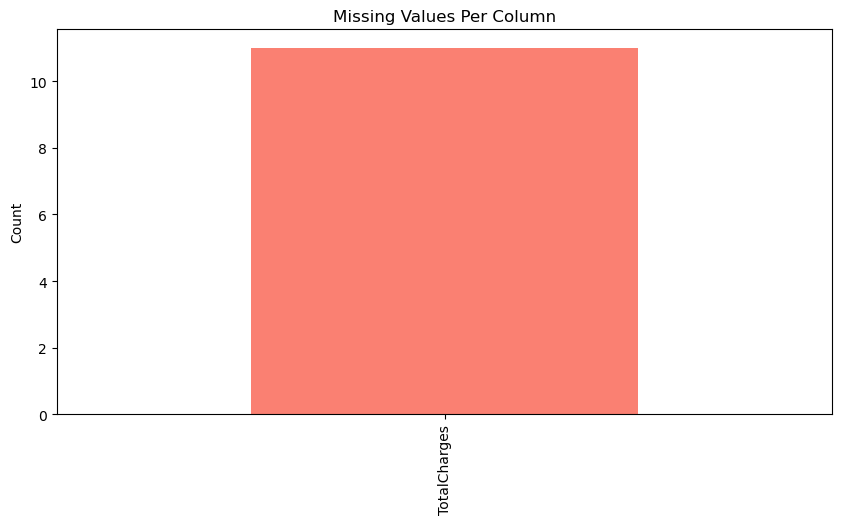

In [2]:
# Check and remove duplicates
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())

# Handle hidden missing values in TotalCharges (blank spaces converted to NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Count missing values per column
missing_counts = df.isnull().sum()
print("\nMissing values per column:\n", missing_counts)

# Missing values bar chart
plt.figure(figsize=(10, 5))
missing_counts[missing_counts > 0].plot(kind='bar', color='salmon')
plt.title('Missing Values Per Column')
plt.ylabel('Count')
plt.show()

# Drop useless columns
# 'customerID' is just a unique identifier and adds no predictive value.
df = df.drop(columns=['customerID'])

# Reasoning for missing values handling:
# TotalCharges has numerical missing values which will be filled with the median in the preprocessing pipeline 
# to avoid skewness from extreme outliers.

### Step 3: Feature Engineering
We create two new features: Avg_Monthly_Charge (dividing total charges by tenure to see spending behavior) and Is_Long_Term (binary indicator if tenure is greater than 24 months). These help the model capture customer loyalty and spending patterns more effectively.

In [3]:
# 1. Average monthly spend efficiency
df['Avg_Monthly_Charge'] = df['TotalCharges'] / (df['tenure'] + 1)

# 2. Long-term customer flag (1 if tenure > 24 months, else 0)
df['Is_Long_Term'] = (df['tenure'] > 24).astype(int)

print("New features created successfully. Current shape:", df.shape)

New features created successfully. Current shape: (7043, 22)


### Step 4: Select Features and Target
We separate our predictor variables (X) from our target variable (y, which is Churn)

In [6]:
X = df.drop(columns=['Churn'])
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0) # Convert target to binary numeric

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 21)
y shape: (7043,)


### Step 5: Train/Test Split
We split the dataset into 80% training and 20% testing sets using train_test_split. We use stratify=y to maintain the same class proportion of churners in both train and test sets, avoiding class imbalance distortion.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

print("\nTraining Class Proportions:\n", y_train.value_counts(normalize=True))
print("\nTesting Class Proportions:\n", y_test.value_counts(normalize=True))

X_train shape: (5634, 21), y_train shape: (5634,)
X_test shape: (1409, 21), y_test shape: (1409,)

Training Class Proportions:
 Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Class Proportions:
 Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


### Step 6: Preprocessing (ColumnTransformer)
We build a ColumnTransformer to handle numerical and categorical columns separately. Numerical columns get missing values filled with the median followed by StandardScaler. Categorical columns get missing values filled with the most frequent value followed by OneHotEncoder. Crucially, all transformers are fitted only on the training set and only transformed on the test set to prevent data leakage.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Pipeline for numerical data: Median Imputation -> Standardization
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical data: Most Frequent Imputation -> One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit-transform on train, transform only on test (Prevents Data Leakage!)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

### Step 7: Final Checks
We perform final sanity checks to verify shapes, confirm zero missing values in both sets, and ensure no test data leakage occurred.

In [9]:
# Print final shapes
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Confirm zero missing values
print("\nMissing values in X_train_processed:", np.isnan(X_train_processed).sum())
print("Missing values in X_test_processed:", np.isnan(X_test_processed).sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

X_train_processed shape: (5634, 47)
X_test_processed shape: (1409, 47)
y_train shape: (5634,)
y_test shape: (1409,)

Missing values in X_train_processed: 0
Missing values in X_test_processed: 0
Missing values in y_train: 0
Missing values in y_test: 0
